In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

importing all the required libraries

In [2]:
df = pd.read_csv("data/loan.csv")

loading the dataset

In [3]:
df.shape

(44993, 14)

### there are 44993 rows and 14 cols

In [4]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [5]:
df.describe()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,44993.000000,4.499300e+04,44993.000000,44993.000000,44993.000000,44993.000000,44993.000000,44993.000000,44993.000000
mean,27.748428,7.990845e+04,5.394528,9583.176761,11.006448,0.139736,5.866557,632.585713,0.222257
std,5.909737,6.332213e+04,5.927159,6314.802655,2.978985,0.087207,3.877167,50.402411,0.415767
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.719500e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704600e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.577800e+04,8.000000,12237.000000,12.990000,0.190000,8.000000,670.000000,0.000000
max,94.000000,2.448661e+06,76.000000,35000.000000,20.000000,0.660000,30.000000,784.000000,1.000000


In [6]:
df.columns

Index(['person_age', 'person_gender', 'person_education', 'person_income',
       'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file', 'loan_status'],
      dtype='str')

In [7]:
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

### no missing values in dataset

In [8]:
df.duplicated().sum()

np.int64(0)

### no duplicate rows found

In [9]:
for col in df.columns:
    print(col, ":", df[col].nunique())

person_age : 56
person_gender : 2
person_education : 5
person_income : 33983
person_emp_exp : 56
person_home_ownership : 4
loan_amnt : 4481
loan_intent : 6
loan_int_rate : 1302
loan_percent_income : 64
cb_person_cred_hist_length : 29
credit_score : 335
previous_loan_defaults_on_file : 2
loan_status : 2


 "person_gender" has 2 unique values, while "person_education" has 5.<br>
 "person_home_ownership" has 4 categories, and "loan_intent" has 6.<br>
 "loan_status" has 2 classes.<br>
 Numerical columns have different numbers of unique values.<br>

### categorical consistency check

In [10]:
cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


person_gender
person_gender
male      24836
female    20157
Name: count, dtype: int64

person_education
person_education
Bachelor       13396
Associate      12026
High School    11970
Master          6980
Doctorate        621
Name: count, dtype: int64

person_home_ownership
person_home_ownership
RENT        23440
MORTGAGE    18485
OWN          2951
OTHER         117
Name: count, dtype: int64

loan_intent
loan_intent
EDUCATION            9151
MEDICAL              8548
VENTURE              7815
PERSONAL             7551
DEBTCONSOLIDATION    7145
HOMEIMPROVEMENT      4783
Name: count, dtype: int64

previous_loan_defaults_on_file
previous_loan_defaults_on_file
Yes    22856
No     22137
Name: count, dtype: int64


C:\Users\vartika singh\AppData\Local\Temp\ipykernel_15664\298200328.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


no categoried with different spellings or extra spaces is present data is cleaned ,so no chnages should be made .

### logical and referential checks

In [11]:
df[df["person_emp_exp"] > df["person_age"]]

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status


In [12]:
print("Age below 18:", (df["person_age"] < 18).sum())

Age below 18: 0


In [13]:
print("Negative experience:", (df["person_emp_exp"] < 0).sum())

Negative experience: 0


In [14]:
print("Negative income:", (df["person_income"] < 0).sum())

Negative income: 0


In [15]:
print("Invalid loan amount:", (df["loan_amnt"] <= 0).sum())

Invalid loan amount: 0


In [16]:
print("Invalid interest rate:", (df["loan_int_rate"] <= 0).sum())

Invalid interest rate: 0


In [17]:
df["loan_status"].value_counts()

loan_status
0    34993
1    10000
Name: count, dtype: int64

### outliers analysis

In [18]:
num_cols = df.select_dtypes(include="number").columns.drop("loan_status")
skewness = df[num_cols].skew().sort_values(ascending=False)
print(skewness)

person_income                 9.694992
person_emp_exp                1.952045
person_age                    1.910603
cb_person_cred_hist_length    1.629395
loan_amnt                     1.179784
loan_percent_income           1.034842
loan_int_rate                 0.213915
credit_score                 -0.615329
dtype: float64


In [19]:
num_cols = df.select_dtypes(include="number").columns.drop("loan_status")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {count} outliers")

person_age: 2181 outliers
person_income: 2214 outliers
person_emp_exp: 1717 outliers
loan_amnt: 2348 outliers
loan_int_rate: 124 outliers
loan_percent_income: 744 outliers
cb_person_cred_hist_length: 1363 outliers
credit_score: 462 outliers


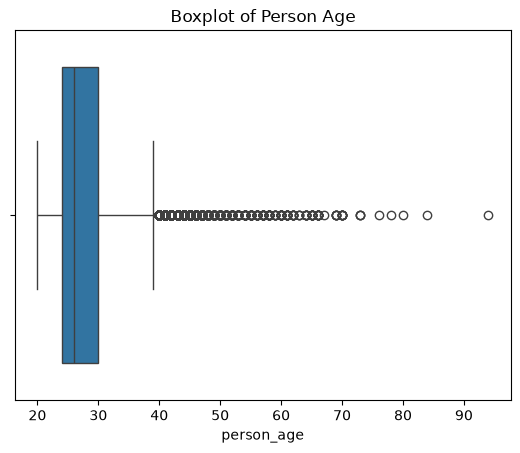

In [20]:
sns.boxplot(x=df["person_age"])
plt.title("Boxplot of Person Age")
plt.show()

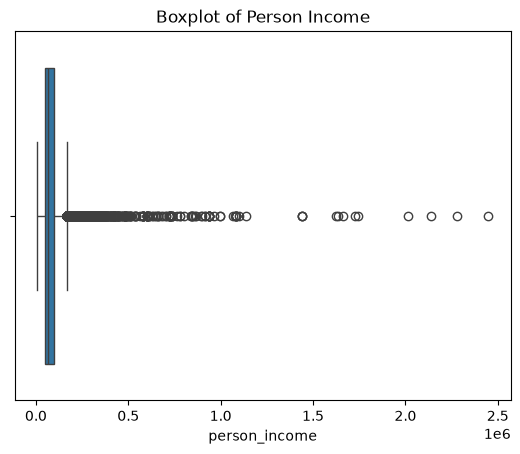

In [21]:
sns.boxplot(x=df["person_income"])
plt.title("Boxplot of Person Income")
plt.show()

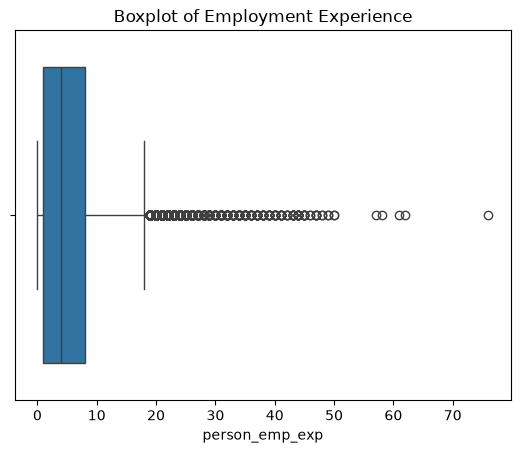

In [22]:
sns.boxplot(x=df["person_emp_exp"])
plt.title("Boxplot of Employment Experience")
plt.show()

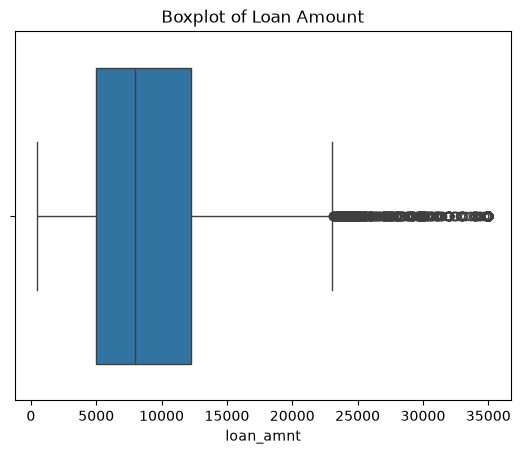

In [23]:
sns.boxplot(x=df["loan_amnt"])
plt.title("Boxplot of Loan Amount")
plt.show()

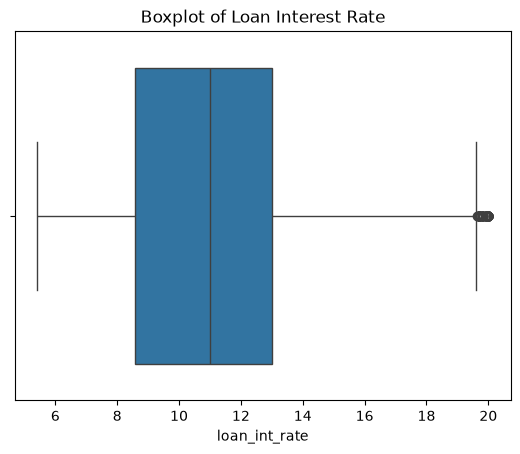

In [24]:
sns.boxplot(x=df["loan_int_rate"])
plt.title("Boxplot of Loan Interest Rate")
plt.show()

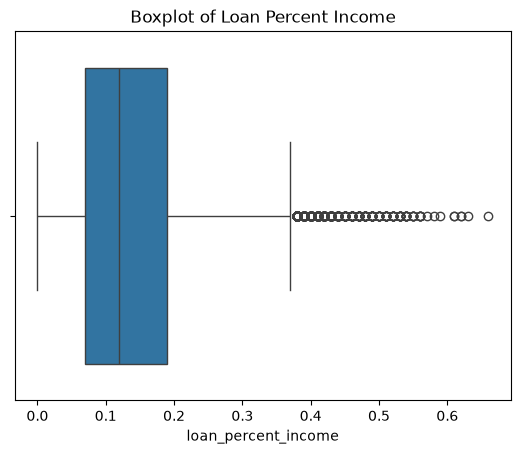

In [25]:
sns.boxplot(x=df["loan_percent_income"])
plt.title("Boxplot of Loan Percent Income")
plt.show()

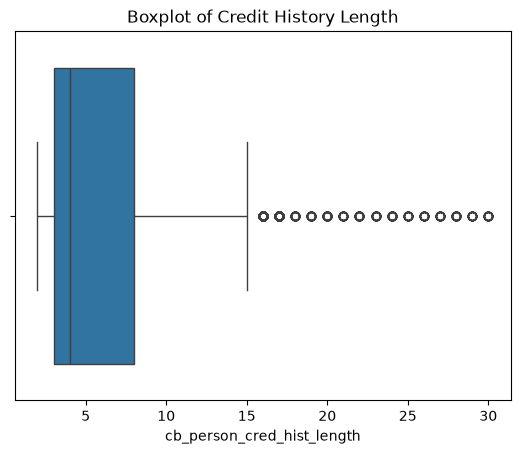

In [26]:
sns.boxplot(x=df["cb_person_cred_hist_length"])
plt.title("Boxplot of Credit History Length")
plt.show()

Outlier are present but all these outliers are valid outlier so we can not change it 

### univariate analysis

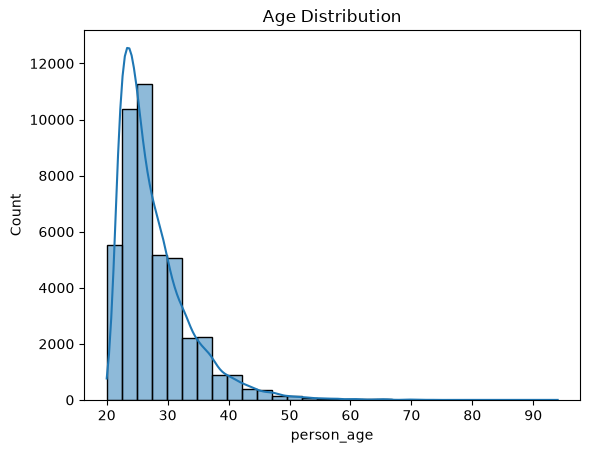

In [27]:
sns.histplot(data=df, x="person_age", bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

Most applicants are between 20 and 30 years old.
The age distribution is right-skewed, with fewer older applicants

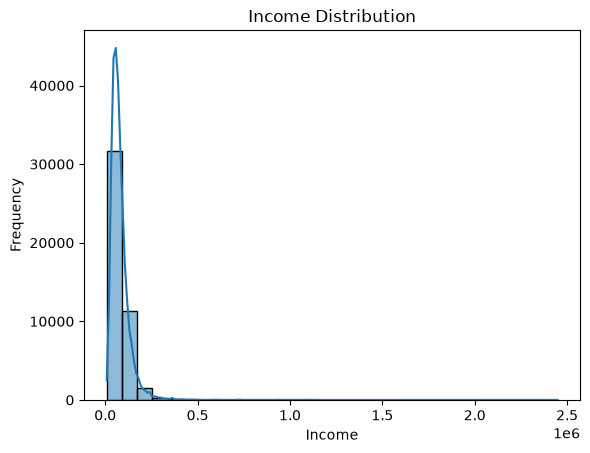

In [28]:
sns.histplot(data=df, x="person_income", bins=30, kde=True)
plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.show()

Most applicants have relatively low annual incomes.<br>
The income distribution is highly right-skewed, with a few applicants earning exceptionally high incomes

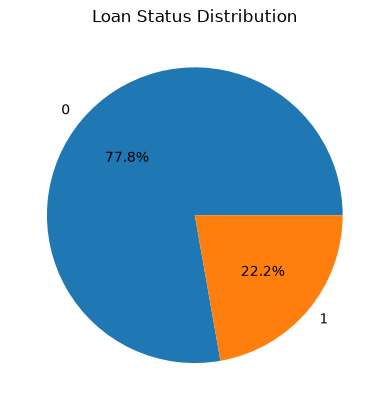

In [29]:
df["loan_status"].value_counts().plot(
    kind="pie", autopct="%1.1f%%")
plt.title("Loan Status Distribution")
plt.ylabel("")
plt.show()

77.8% of applicants belong to class 0, while 22.2% belong to class 1.<br>
The target variable is imbalanced, with class 0 being more common.

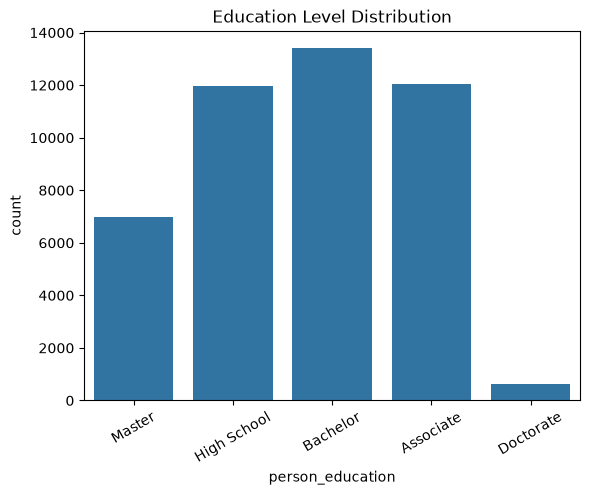

In [30]:
sns.countplot(data=df, x="person_education")
plt.title("Education Level Distribution")
plt.xticks(rotation=30)
plt.show()

Applicants with a Bachelor's degree form the largest group.<br>
Doctorate holders are the least represented group.

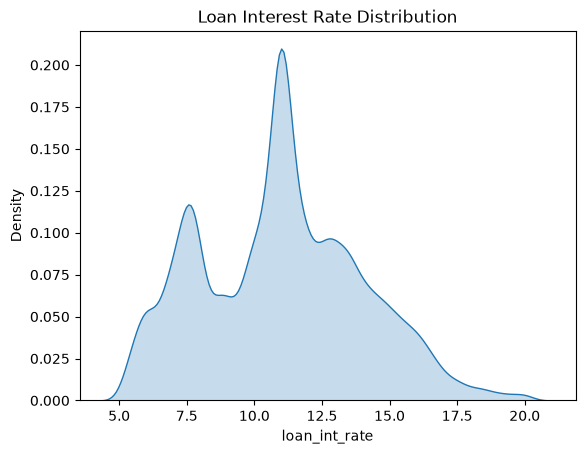

In [31]:
sns.kdeplot(data=df, x="loan_int_rate", fill=True)
plt.title("Loan Interest Rate Distribution")
plt.show()

Most interest rates fall between approximately 8% and 14%.<br>
The distribution has multiple peaks, with the highest peak around 11%.

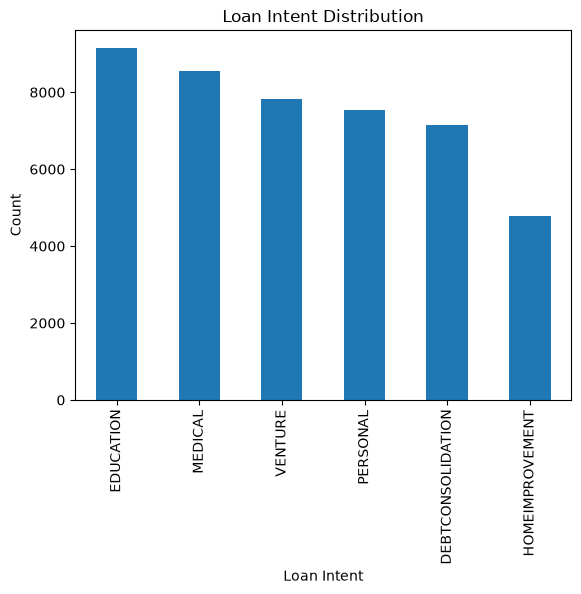

In [32]:
df["loan_intent"].value_counts().plot(kind="bar")
plt.title("Loan Intent Distribution")
plt.xlabel("Loan Intent")
plt.ylabel("Count")
plt.show()

Education is the most common loan purpose.
Home improvement is the least common loan purpose.

### bivariate analysis

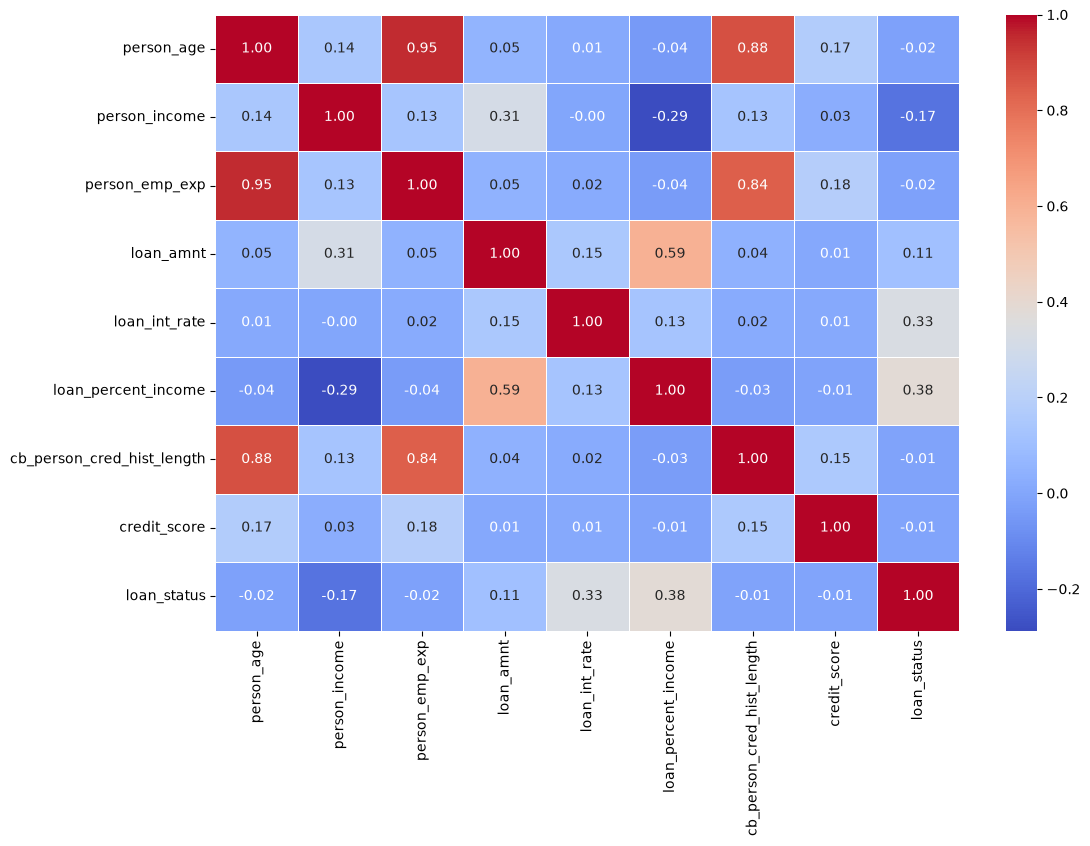

In [33]:
num_df = df.select_dtypes(include="number")
plt.figure(figsize=(12, 8))
sns.heatmap(num_df.corr(), annot=True , cmap="coolwarm", fmt=".2f",linewidths=0.5)
plt.show()

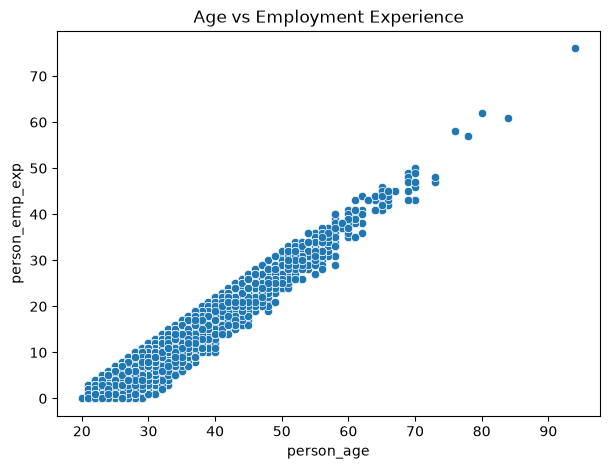

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="person_age", y="person_emp_exp")
plt.title("Age vs Employment Experience")
plt.show()

age and employment experience have a strong positive correlation of 0.95. Older applicants generally tend to have more work experience.


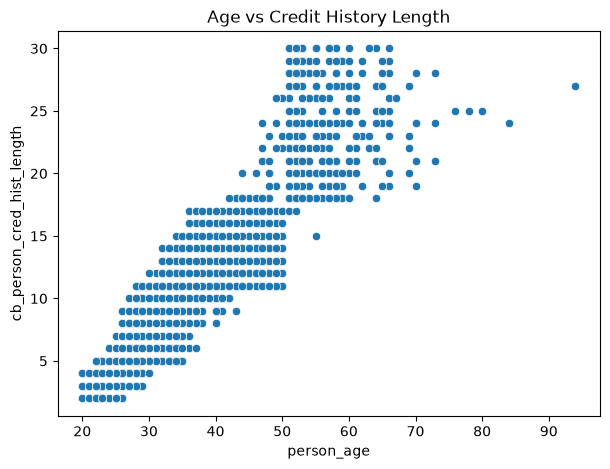

In [35]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="person_age", y="cb_person_cred_hist_length")
plt.title("Age vs Credit History Length")
plt.show()

Age and credit history length have a strong positive correlation of 0.88

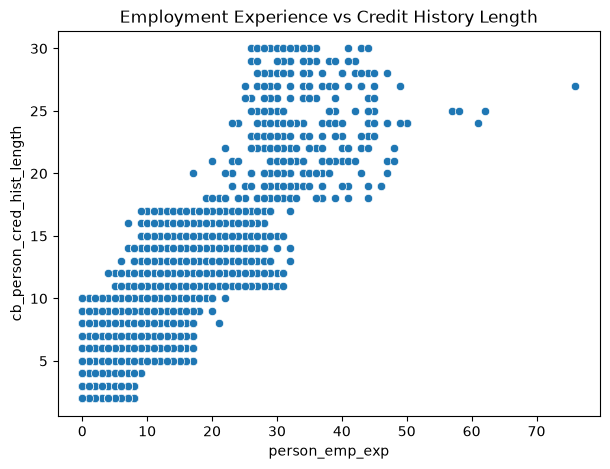

In [36]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="person_emp_exp", y="cb_person_cred_hist_length")
plt.title("Employment Experience vs Credit History Length")
plt.show()

Employment experience and credit history length have a strong positive correlation of 0.84.

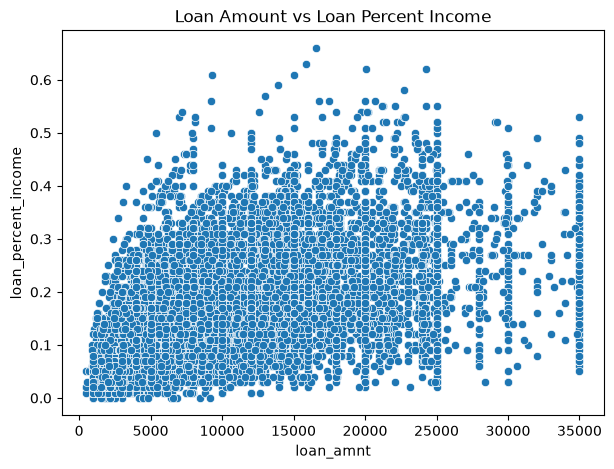

In [37]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="loan_amnt", y="loan_percent_income")
plt.title("Loan Amount vs Loan Percent Income")
plt.show()

Loan amount and loan percent income have a positive correlation of 0.59. Higher loan amounts tend to be associated with a higher proportion of income borrowed.

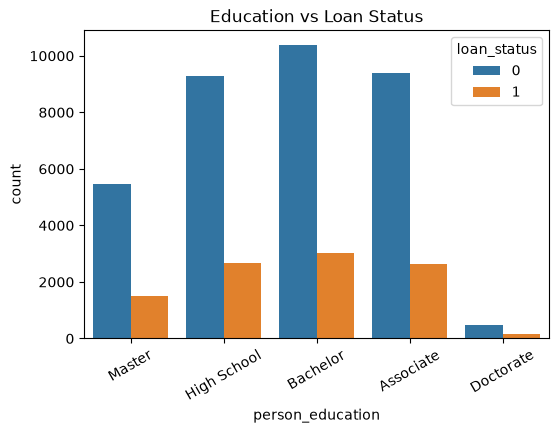

In [38]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="person_education", hue="loan_status")
plt.title("Education vs Loan Status")
plt.xticks(rotation=30)
plt.show()

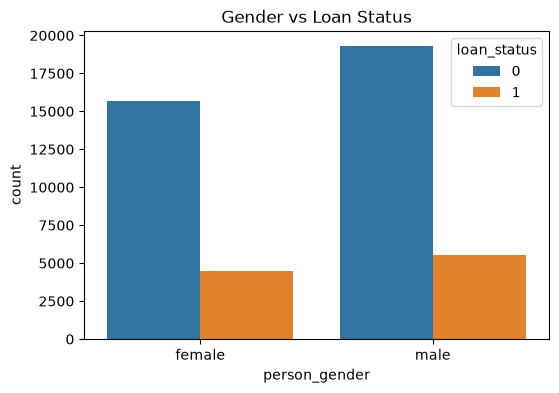

In [39]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="person_gender", hue="loan_status")
plt.title("Gender vs Loan Status")
plt.show()

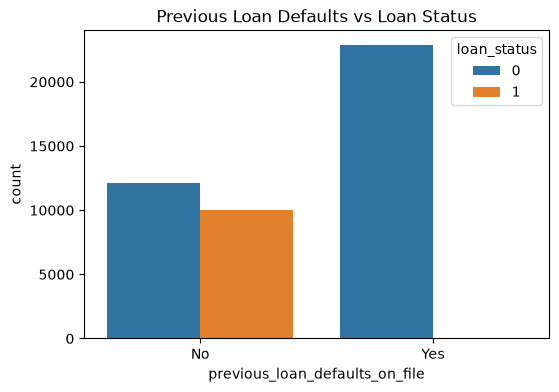

In [40]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="previous_loan_defaults_on_file", hue="loan_status")
plt.title("Previous Loan Defaults vs Loan Status")
plt.show()

### multivariate analysis

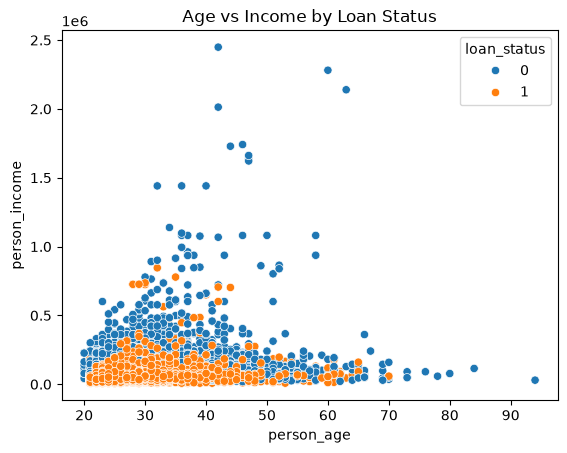

In [41]:
sns.scatterplot(data=df, x="person_age", y="person_income", hue="loan_status")
plt.title("Age vs Income by Loan Status")
plt.show()

Most applicants are between 25 and 40 years old, with income concentrated at lower levels.<br>
Class 0 appears more frequently across higher income levels than class 1.

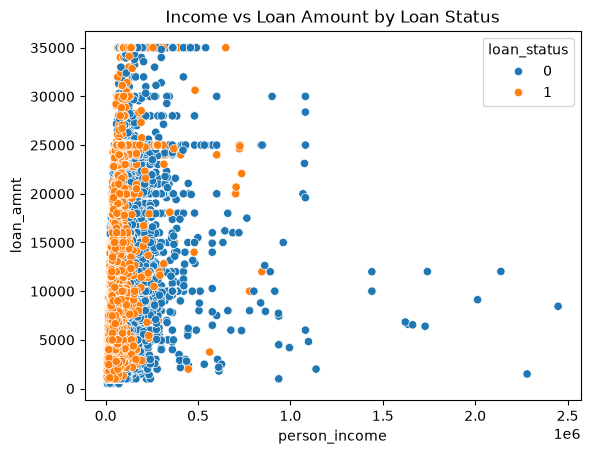

In [42]:
sns.scatterplot(data=df, x="person_income", y="loan_amnt", hue="loan_status")
plt.title("Income vs Loan Amount by Loan Status")
plt.show()

Most applicants have lower incomes, while loan amounts vary widely.<br>
Class 0 is more common among higher-income applicants, but income alone does not determine loan status.

### MODEL TRAINING  

### selecting target cols

In [43]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (44993, 13)
y shape: (44993,)


### train test split

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (35994, 13)
X_test: (8999, 13)


In [45]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score'],
      dtype='str')
Categorical columns: Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='str')


### encoding and scaling

In [72]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

### LOGISTIC REGRESSTION

In [73]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000,class_weight="balanced"))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [74]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score)

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

alr = accuracy_score(y_test, y_pred_lr)
plr = precision_score(y_test, y_pred_lr, zero_division=0)
rlr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Accuracy:", alr)
print("Precision:", plr)
print("Recall:", rlr)
print("F1 Score:", f1_lr)
print("ROC-AUC:", roc_auc_lr)

Accuracy: 0.8490943438159796
Precision: 0.6063618290258449
Recall: 0.915
F1 Score: 0.7293742526903149
ROC-AUC: 0.9521642377482498


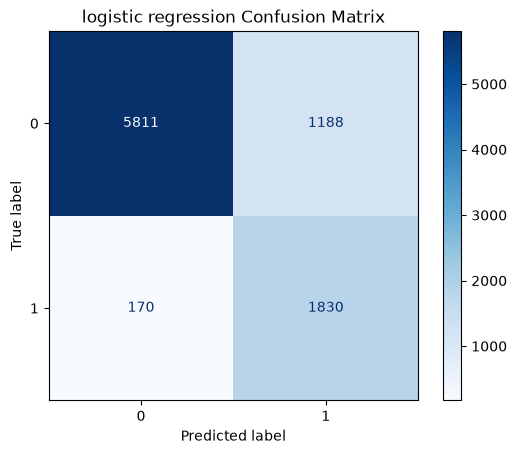

In [75]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr)
disp.plot(cmap="Blues")
plt.title("logistic regression Confusion Matrix")
plt.show()

### RANDOM FOREST

In [76]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [77]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

arf = accuracy_score(y_test, y_pred_rf)
prf = precision_score(y_test, y_pred_rf, zero_division=0)
rrf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Accuracy:", arf)
print("Precision:", prf)
print("Recall:", rrf)
print("F1 Score:", f1_rf)
print("ROC-AUC:", roc_auc_rf)

Accuracy: 0.9212134681631292
Precision: 0.802625410220347
Recall: 0.856
F1 Score: 0.8284539075731914
ROC-AUC: 0.9732276039434204


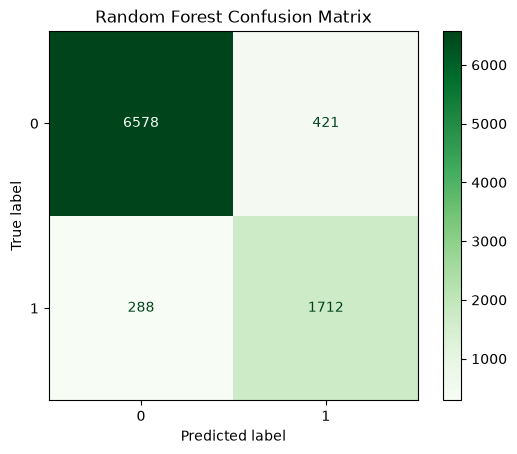

In [78]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp.plot(cmap="Greens")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [79]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### XG_BOOST

In [80]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=3.5,
    random_state=42,
    eval_metric="logloss"
))])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [81]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

axgb = accuracy_score(y_test, y_pred_xgb)
pxgb = precision_score(y_test, y_pred_xgb, zero_division=0)
rxgb = recall_score(y_test, y_pred_xgb, zero_division=0)
f1_xgb = f1_score(y_test, y_pred_xgb, zero_division=0)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("Accuracy:", axgb)
print("Precision:", pxgb)
print("Recall:",rxgb)
print("F1 Score:", f1_xgb)
print("ROC-AUC:", roc_auc_xgb)

Accuracy: 0.8925436159573286
Precision: 0.6938086303939962
Recall: 0.9245
F1 Score: 0.7927116827438371
ROC-AUC: 0.9743493713387628


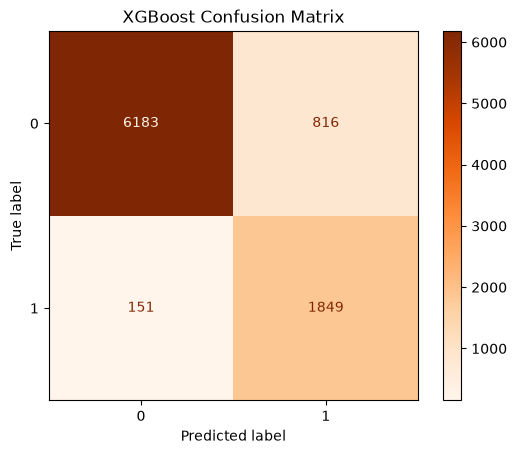

In [82]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay( confusion_matrix=cm_xgb)
disp.plot(cmap="Oranges")
plt.title("XGBoost Confusion Matrix")
plt.show()

### COMPARISION TABLE

In [85]:
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression","Random Forest","XGBoost"],
    "Accuracy": [alr, arf, axgb],
    "Precision": [plr, prf, pxgb],
    "Recall": [rlr, rrf, rxgb],
    "F1 Score": [f1_lr, f1_rf, f1_xgb],
    "ROC-AUC": [roc_auc_lr, roc_auc_rf, roc_auc_xgb]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.849094,0.606362,0.9150,0.729374,0.952164
1,Random Forest,0.921213,0.802625,0.8560,0.828454,0.973228
2,XGBoost,0.892544,0.693809,0.9245,0.792712,0.974349


### SAVING BEST MODEL RANDOM FOREST

In [86]:
import joblib
joblib.dump(rf_model, "loan_prediction_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [87]:
model = joblib.load("loan_prediction_model.pkl")